# 6.3 — Traditional Lexical Classification: Revised Explainable TF-IDF Methodology

## Purpose

This notebook is the **final revised traditional-method experiment** for the Research Commons Māori-origin classification study.

It is deliberately restricted to traditional lexical methods:

- transparent keyword retrieval baselines;
- TF-IDF representations;
- logistic regression;
- class weighting;
- training-only cross-validation;
- probability calibration;
- global coefficient analysis;
- exact per-record feature contributions;
- lexical-condition analysis;
- threshold versus review-burden analysis;
- reference-relative disagreement analysis.

It does **not** use or inspect any LLM/embedding prediction, generated confidence, or generated reason.

The existing `classification_label` is used only as:

1. the supervised target on the training split; and
2. the comparison/reference label on the held-out test split.

All reported performance therefore means **agreement with the existing reference labels**, not Māori-expert-validated ground truth.

---

## Research questions

**RQ-T1 — Keyword retrieval**  
How far can transparent lexical retrieval go when Māori-related terminology is explicit?

**RQ-T2 — Learned lexical classification**  
How effectively can TF-IDF + logistic regression learn the reference-label distinction from repository metadata?

**RQ-T3 — Phrase representation**  
Do additional bigram/trigram features improve lexical discrimination beyond a fixed unigram representation?

**RQ-T4 — Class imbalance**  
Holding representation fixed, what changes when logistic regression uses class weighting?

**RQ-T5 — Global interpretability**  
Which field-specific lexical features are most strongly associated with each reference class?

**RQ-T6 — Local interpretability**  
For an individual record, which exact TF-IDF features contributed to the logistic-regression decision?

**RQ-T7 — Lexical conditions**  
How does performance change when metadata contains strong Māori-specific phrases, only general Māori lexical cues, only broader contextual vocabulary, or none of these selected cues?

**RQ-T8 — Screening trade-off**  
How do decision thresholds change Māori-reference recall, precision, and the number of records surfaced for repository review?

**RQ-T9 — Probability reliability**  
Can a probability transformation learned only from training data provide a more interpretable per-record Māori-reference probability?

---

## Important design changes from the exploratory notebooks

- The held-out test set is **not used to choose the TF-IDF configuration**.
- Candidate configurations are compared using 5-fold stratified cross-validation on the training split only.
- Title, subjects, and abstract are vectorized **separately**, preventing n-grams from crossing metadata-field boundaries.
- The phrase condition adds a separate bigram/trigram feature block; it does **not replace or compete with the unigram block**.
- The keyword vocabulary is diagnostic and transparent. Broad terms such as `research` and the repository-specific place name `Waikato` are not treated as Māori-positive triggers.
- Lexical-condition groups are defined from text only, **not from the reference label**.
- Calibration is learned from out-of-fold training decision scores and applied to the final single fitted classifier, so the probability and explanation refer to the same model.
- Per-record explanations include the intercept and verify reconstruction of the exact logistic decision score.

## 0. Install dependencies

In [1]:
!pip -q install datasets huggingface_hub scikit-learn pandas numpy matplotlib joblib pyarrow scipy

## 1. Imports, reproducibility, and output directory

In [2]:
import os
import re
import json
import random
import warnings
import unicodedata
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import sparse

from datasets import load_dataset
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    average_precision_score,
    confusion_matrix,
    brier_score_loss,
    precision_recall_curve,
)
from sklearn.calibration import calibration_curve

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

DATASET_ID = "dinushiTJ/nz_research_commons_classification"
LABEL_COL = "classification_label"
ID_COL = "record_id_hash"

CONTENT_FIELDS = ["title", "subjects", "abstract"]

N_SPLITS = 5
MIN_DF = 2
LR_C = 1.0
LR_SOLVER = "liblinear"
LR_MAX_ITER = 3000

# Fixed feature budgets. The phrase condition ADDS phrase blocks while keeping
# the exact same unigram blocks.
UNIGRAM_MAX = {
    "title": 2500,
    "subjects": 3500,
    "abstract": 9000,
}
PHRASE_MAX = {
    "title": 1800,
    "subjects": 2800,
    "abstract": 7000,
}

BOOTSTRAP_N = 2000

OUTPUT_DIR = (
    Path("/content/tfidf_traditional_revised_outputs")
    if Path("/content").exists()
    else Path("./tfidf_traditional_revised_outputs")
)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print("Dataset:", DATASET_ID)
print("Content fields:", CONTENT_FIELDS)
print("Outputs:", OUTPUT_DIR.resolve())

Dataset: dinushiTJ/nz_research_commons_classification
Content fields: ['title', 'subjects', 'abstract']
Outputs: /content/tfidf_traditional_revised_outputs


## 2. Load the fixed study splits

The notebook uses the existing study split and does **not** create a new train/test split.

Expected counts:

- train: 13,271
- held-out test: 3,318
- train Māori-reference: 1,469
- train non-Māori-reference: 11,802
- test Māori-reference: 367
- test non-Māori-reference: 2,951

The held-out test set is reserved until the methodology and final configuration have been chosen using training-only cross-validation.

In [3]:
dataset = load_dataset(DATASET_ID)

assert "train" in dataset and "test" in dataset, "Expected train and test splits."
assert LABEL_COL in dataset["train"].column_names
assert LABEL_COL in dataset["test"].column_names

train_df = dataset["train"].to_pandas().copy()
test_df = dataset["test"].to_pandas().copy()

print(dataset)
print("Train rows:", len(train_df))
print("Test rows:", len(test_df))
print("Columns:", train_df.columns.tolist())

README.md:   0%|          | 0.00/1.12k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 83.2MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/13271 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3318 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['title', 'authors', 'subjects', 'abstract', 'text', 'record_id_hash', 'prompt', 'token_count', 'classification_label', 'classification_reason', 'year', 'classification_confidence', 'embedding_text', 'embedding_token_count', 'conversations'],
        num_rows: 13271
    })
    test: Dataset({
        features: ['title', 'authors', 'subjects', 'abstract', 'text', 'record_id_hash', 'prompt', 'token_count', 'classification_label', 'classification_reason', 'year', 'classification_confidence', 'embedding_text', 'embedding_token_count', 'conversations'],
        num_rows: 3318
    })
})
Train rows: 13271
Test rows: 3318
Columns: ['title', 'authors', 'subjects', 'abstract', 'text', 'record_id_hash', 'prompt', 'token_count', 'classification_label', 'classification_reason', 'year', 'classification_confidence', 'embedding_text', 'embedding_token_count', 'conversations']


## 3. Decode reference labels safely

In [4]:
label_feature = dataset["train"].features[LABEL_COL]

def decode_label(value):
    if hasattr(label_feature, "int2str") and not isinstance(value, str):
        return label_feature.int2str(int(value))
    value = str(value)
    if value in {"0", "maori_origin"}:
        return "maori_origin"
    if value in {"1", "non_maori_origin"}:
        return "non_maori_origin"
    raise ValueError(f"Unexpected label value: {value!r}")

for df in (train_df, test_df):
    df["reference_label"] = df[LABEL_COL].map(decode_label)
    # Analysis convention: Māori-reference is the positive class.
    df["y"] = (df["reference_label"] == "maori_origin").astype(int)

print("Training reference labels:")
print(train_df["reference_label"].value_counts())
print("\nHeld-out test reference labels:")
print(test_df["reference_label"].value_counts())

expected = {
    "train_total": 13271,
    "test_total": 3318,
    "train_maori": 1469,
    "train_non_maori": 11802,
    "test_maori": 367,
    "test_non_maori": 2951,
}
observed = {
    "train_total": len(train_df),
    "test_total": len(test_df),
    "train_maori": int(train_df["y"].sum()),
    "train_non_maori": int((1 - train_df["y"]).sum()),
    "test_maori": int(test_df["y"].sum()),
    "test_non_maori": int((1 - test_df["y"]).sum()),
}
for key, exp in expected.items():
    if observed[key] != exp:
        warnings.warn(f"{key}: expected {exp}, observed {observed[key]}. Dataset may have changed.")

observed

Training reference labels:
reference_label
non_maori_origin    11802
maori_origin         1469
Name: count, dtype: int64

Held-out test reference labels:
reference_label
non_maori_origin    2951
maori_origin         367
Name: count, dtype: int64


{'train_total': 13271,
 'test_total': 3318,
 'train_maori': 1469,
 'train_non_maori': 11802,
 'test_maori': 367,
 'test_non_maori': 2951}

## 4. Prepare field-aware lexical inputs

The primary traditional lexical input is:

- title
- subjects
- abstract

These fields remain separate throughout TF-IDF vectorization. This has two benefits:

1. phrases cannot accidentally cross from one metadata field into another; and
2. explanations can identify whether evidence came from the title, subjects, or abstract.

Author names and publication year are excluded from the primary lexical model to reduce researcher-identity and temporal shortcuts.

In [5]:
def clean_value(value):
    if value is None:
        return ""
    if isinstance(value, (list, tuple, set, np.ndarray)):
        return " ; ".join(str(x) for x in value if x is not None)
    try:
        if pd.isna(value):
            return ""
    except Exception:
        pass
    return str(value)

for df in (train_df, test_df):
    for field in CONTENT_FIELDS:
        if field not in df.columns:
            warnings.warn(f"Missing field {field!r}; replacing with empty text.")
            df[field] = ""
        df[f"{field}_text"] = df[field].map(clean_value).fillna("").astype(str)

MODEL_COLUMNS = [f"{f}_text" for f in CONTENT_FIELDS]
X_train_df = train_df[MODEL_COLUMNS].copy()
X_test_df = test_df[MODEL_COLUMNS].copy()
y_train = train_df["y"].to_numpy(dtype=int)
y_test = test_df["y"].to_numpy(dtype=int)

print(X_train_df.head(2).to_string(index=False))

                                                 title_text subjects_text                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                                               

# Part A — Transparent lexical retrieval baselines

## 5. Frozen diagnostic vocabularies

The lexical vocabularies below are **not an attempt to encode the full Māori-origin definition as hand-written rules**.

They are diagnostic sets used to answer a simpler question: what kinds of lexical evidence are explicitly visible in the metadata?

Three levels are kept separate:

1. **specific Māori phrases** — relatively specific multi-word expressions;
2. **general Māori lexical cues** — Māori-related words that may still appear incidentally;
3. **broad contextual cues** — New Zealand/Pacific/Indigenous/domain vocabulary that is not Māori-specific.

`research` is intentionally excluded because it is nearly universal in a research repository.  
`Waikato` is intentionally excluded as a Māori-positive trigger because it is also the institution/repository location.

In [6]:
# Matching is normalized to remove macrons only for rule lookup.
SPECIFIC_MAORI_PHRASES = [
    "te reo maori",
    "kaupapa maori",
    "matauranga maori",
    "tino rangatiratanga",
    "te tiriti o waitangi",
    "treaty of waitangi",
    "waitangi tribunal",
    "treaty settlement",
    "maori data sovereignty",
    "maori health",
    "maori education",
    "maori land",
    "maori language",
    "maori culture",
    "maori identity",
    "maori knowledge",
    "maori methodology",
    "mana whenua",
    "tangata whenua",
    "mahinga kai",
]

GENERAL_MAORI_CUES = [
    "maori",
    "whanau",
    "hapu",
    "iwi",
    "marae",
    "tikanga",
    "whakapapa",
    "matauranga",
    "kaitiakitanga",
    "taonga",
    "whenua",
    "rohe",
    "urupa",
    "rangatiratanga",
]

BROAD_CONTEXT_CUES = [
    "aotearoa",
    "new zealand",
    "indigenous",
    "pacific",
    "community",
    "health",
    "education",
    "environment",
    "colonisation",
    "colonization",
]

def normalize_for_rules(text):
    text = clean_value(text).casefold()
    text = unicodedata.normalize("NFKD", text)
    text = "".join(ch for ch in text if not unicodedata.combining(ch))
    text = re.sub(r"[^a-z0-9\\s'-]+", " ", text)
    text = re.sub(r"\\s+", " ", text).strip()
    return text

def contains_term(normalized_text, term):
    term = normalize_for_rules(term)
    pattern = r"(?<!\\w)" + re.escape(term).replace(r"\\ ", r"\\s+") + r"(?!\\w)"
    return re.search(pattern, normalized_text) is not None

def combined_text(row):
    return " \\n ".join(clean_value(row.get(f"{f}_text", "")) for f in CONTENT_FIELDS)

def lexical_probe(row):
    text = normalize_for_rules(combined_text(row))
    specific = [t for t in SPECIFIC_MAORI_PHRASES if contains_term(text, t)]
    general = [t for t in GENERAL_MAORI_CUES if contains_term(text, t)]
    broad = [t for t in BROAD_CONTEXT_CUES if contains_term(text, t)]

    # Remove redundant generic cue "maori" from display when a more specific
    # Māori phrase already contains it; the raw cue is still available by matching.
    return {
        "specific_hits": list(dict.fromkeys(specific)),
        "general_hits": list(dict.fromkeys(general)),
        "broad_hits": list(dict.fromkeys(broad)),
        "has_specific": bool(specific),
        "has_general": bool(general),
        "has_broad": bool(broad),
    }

for df in (train_df, test_df):
    probes = df.apply(lexical_probe, axis=1)
    df["specific_hits"] = probes.map(lambda d: json.dumps(d["specific_hits"], ensure_ascii=False))
    df["general_maori_hits"] = probes.map(lambda d: json.dumps(d["general_hits"], ensure_ascii=False))
    df["broad_context_hits"] = probes.map(lambda d: json.dumps(d["broad_hits"], ensure_ascii=False))
    df["has_specific_maori_phrase"] = probes.map(lambda d: d["has_specific"])
    df["has_general_maori_cue"] = probes.map(lambda d: d["has_general"])
    df["has_broad_context_cue"] = probes.map(lambda d: d["has_broad"])

print("Training lexical-condition counts:")
print(pd.DataFrame({
    "specific": [int(train_df["has_specific_maori_phrase"].sum())],
    "general": [int(train_df["has_general_maori_cue"].sum())],
    "broad": [int(train_df["has_broad_context_cue"].sum())],
}))

Training lexical-condition counts:
   specific  general  broad
0       579     1451   7305


## 6. Two transparent keyword retrieval baselines

These are intentionally simple retrieval strategies, not "reasoning" systems.

**Strict keyword baseline**  
A record is surfaced only when at least one specific Māori phrase is present.

**Inclusive keyword baseline**  
A record is surfaced when either a specific Māori phrase or a general Māori lexical cue is present.

There are no hand-crafted numerical scores and no invented confidence levels. The comparison tells us the recall/precision cost of making lexical search more inclusive.

In [7]:
train_df["keyword_strict_pred"] = train_df["has_specific_maori_phrase"].astype(int)
test_df["keyword_strict_pred"] = test_df["has_specific_maori_phrase"].astype(int)

train_df["keyword_inclusive_pred"] = (
    train_df["has_specific_maori_phrase"] | train_df["has_general_maori_cue"]
).astype(int)
test_df["keyword_inclusive_pred"] = (
    test_df["has_specific_maori_phrase"] | test_df["has_general_maori_cue"]
).astype(int)

## 7. Evaluation helpers

In [8]:
def metric_row(name, y_true, y_pred, score=None):
    y_true = np.asarray(y_true, dtype=int)
    y_pred = np.asarray(y_pred, dtype=int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()

    return {
        "model": name,
        "accuracy": accuracy_score(y_true, y_pred),
        "macro_f1": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "maori_precision": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "maori_recall": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "maori_f1": f1_score(y_true, y_pred, pos_label=1, zero_division=0),
        "auprc": np.nan if score is None else average_precision_score(y_true, score),
        "predicted_maori": int(y_pred.sum()),
        "tp": int(tp),
        "fn": int(fn),
        "fp": int(fp),
        "tn": int(tn),
    }

def show_confusion(y_true, y_pred, title, save_name=None):
    cm = confusion_matrix(y_true, y_pred, labels=[1, 0])
    fig, ax = plt.subplots(figsize=(5.4, 4.4))
    ax.imshow(cm)
    ax.set_xticks([0, 1], labels=["Māori-origin", "Non-Māori-origin"])
    ax.set_yticks([0, 1], labels=["Māori-origin", "Non-Māori-origin"])
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Reference")
    ax.set_title(title)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, int(cm[i, j]), ha="center", va="center")
    fig.tight_layout()
    if save_name:
        fig.savefig(OUTPUT_DIR / save_name, dpi=200, bbox_inches="tight")
    plt.show()
    return cm

## 8. Training-only audit of lexical cue prevalence

Per-term prevalence is examined on the **training data**, not mined from the held-out test set.

This lets us see which apparently Māori-related cues are actually specific and which occur substantially in the non-Māori reference class.

In [9]:
all_probe_terms = (
    [("specific", t) for t in SPECIFIC_MAORI_PHRASES]
    + [("general", t) for t in GENERAL_MAORI_CUES]
    + [("broad", t) for t in BROAD_CONTEXT_CUES]
)

norm_train = train_df.apply(lambda r: normalize_for_rules(combined_text(r)), axis=1)
rows = []
for category, term in all_probe_terms:
    hits = norm_train.map(lambda text: contains_term(text, term))
    pos = train_df["y"].eq(1)
    neg = train_df["y"].eq(0)
    rows.append({
        "category": category,
        "term": term,
        "train_docs_total": int(hits.sum()),
        "train_maori_docs": int((hits & pos).sum()),
        "train_non_maori_docs": int((hits & neg).sum()),
        "train_maori_prevalence": float(hits[pos].mean()),
        "train_non_maori_prevalence": float(hits[neg].mean()),
        "prevalence_difference": float(hits[pos].mean() - hits[neg].mean()),
    })

lexical_prevalence_df = pd.DataFrame(rows).sort_values(
    ["category", "train_maori_prevalence"], ascending=[True, False]
)
lexical_prevalence_df.to_csv(
    OUTPUT_DIR / "training_lexical_probe_prevalence.csv", index=False
)
display(lexical_prevalence_df.round(4))

,category,term,train_docs_total,train_maori_docs,train_non_maori_docs,train_maori_prevalence,train_non_maori_prevalence,prevalence_difference
35,broad,new zealand,4402,771,3631,0.5248,0.3077,0.2172
36,broad,indigenous,654,429,225,0.2920,0.0191,0.2730
34,broad,aotearoa,813,394,419,0.2682,0.0355,0.2327
40,broad,education,1765,296,1469,0.2015,0.1245,0.0770
39,broad,health,1097,245,852,0.1668,0.0722,0.0946
41,broad,environment,2274,242,2032,0.1647,0.1722,-0.0074
38,broad,community,1202,223,979,0.1518,0.0830,0.0689
42,broad,colonisation,146,99,47,0.0674,0.0040,0.0634
37,broad,pacific,361,70,291,0.0477,0.0247,0.0230
43,broad,colonization,52,17,35,0.0116,0.0030,0.0086


# Part B — Field-aware TF-IDF representations

## 9. Build controlled feature blocks

The unigram representation is fixed across all relevant configurations.

The phrase condition adds separate **bigram/trigram** blocks. This means useful unigrams are not displaced merely because phrases compete for the same `max_features` budget.

Each metadata field has its own vectorizer, so n-grams cannot cross field boundaries.

In [13]:
def make_tfidf(ngram_range, max_features, min_df_param):
    return TfidfVectorizer(
        lowercase=True,
        min_df=min_df_param,
        max_features=max_features,
        ngram_range=ngram_range,
        norm="l2",
        sublinear_tf=False,
        strip_accents=None,
        token_pattern=r"(?u)\b\w\w+\b",
    )

def make_feature_transformer(include_phrases=False, min_df_param=MIN_DF):
    transformers = []

    # Fixed unigram blocks
    for field in CONTENT_FIELDS:
        transformers.append((
            f"{field}_uni",
            make_tfidf((1, 1), UNIGRAM_MAX[field], min_df_param),
            f"{field}_text",
        ))

    # Additive bigram/trigram blocks
    if include_phrases:
        for field in CONTENT_FIELDS:
            transformers.append((
                f"{field}_phrase",
                make_tfidf((2, 3), PHRASE_MAX[field], min_df_param),
                f"{field}_text",
            ))

    return ColumnTransformer(
        transformers=transformers,
        remainder="drop",
        sparse_threshold=1.0,
        verbose_feature_names_out=True,
    )

def make_classifier(class_weight=None):
    return LogisticRegression(
        C=LR_C,
        solver=LR_SOLVER,
        max_iter=LR_MAX_ITER,
        class_weight=class_weight,
        random_state=SEED,
    )

def make_pipeline(include_phrases=False, class_weight=None, min_df_param=MIN_DF):
    return Pipeline([
        ("features", make_feature_transformer(include_phrases=include_phrases, min_df_param=min_df_param)),
        ("lr", make_classifier(class_weight=class_weight)),
    ])

CONFIGS = {
    "unigram_unweighted": {
        "include_phrases": False,
        "class_weight": None,
    },
    "unigram_balanced": {
        "include_phrases": False,
        "class_weight": "balanced",
    },
    "unigram_plus_phrases_unweighted": {
        "include_phrases": True,
        "class_weight": None,
    },
    "unigram_plus_phrases_balanced": {
        "include_phrases": True,
        "class_weight": "balanced",
    },
}

# Show the exact class weights implied by sklearn's "balanced" rule.
n = len(y_train)
n_pos = int(y_train.sum())
n_neg = int((1 - y_train).sum())
balanced_weight_maori = n / (2 * n_pos)
balanced_weight_non_maori = n / (2 * n_neg)

print("Balanced class-weight values:")
print({
    "maori_origin": balanced_weight_maori,
    "non_maori_origin": balanced_weight_non_maori,
})


Balanced class-weight values:
{'maori_origin': 4.517018379850239, 'non_maori_origin': 0.5622352143704457}


# Part C — Training-only model comparison

## 10. Five-fold stratified cross-validation

All candidate TF-IDF configurations are compared **only on the training split**.

For every configuration we save:

- out-of-fold prediction;
- out-of-fold Māori score/probability;
- out-of-fold decision score;
- fold-level metrics.

The held-out test set is not used here.

In [14]:
skf = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)

cv_store = {}
fold_rows = []

# MIN_DF is now explicitly passed to make_pipeline

for config_name, cfg in CONFIGS.items():
    print(f"\n=== CV: {config_name} ===")
    oof_pred = np.zeros(len(train_df), dtype=int)
    oof_prob = np.zeros(len(train_df), dtype=float)
    oof_decision = np.zeros(len(train_df), dtype=float)
    oof_fold = np.full(len(train_df), -1, dtype=int)

    for fold, (tr_idx, va_idx) in enumerate(skf.split(X_train_df, y_train), start=1):
        pipe = make_pipeline(
            include_phrases=cfg["include_phrases"],
            class_weight=cfg["class_weight"],
            min_df_param=1 # Explicitly pass 1 for min_df during CV
        )
        pipe.fit(X_train_df.iloc[tr_idx], y_train[tr_idx])

        pred = pipe.predict(X_train_df.iloc[va_idx])
        prob = pipe.predict_proba(X_train_df.iloc[va_idx])[:, 1]
        decision = pipe.decision_function(X_train_df.iloc[va_idx])

        oof_pred[va_idx] = pred
        oof_prob[va_idx] = prob
        oof_decision[va_idx] = decision
        oof_fold[va_idx] = fold

        row = metric_row(
            f"{config_name}_fold_{fold}",
            y_train[va_idx],
            pred,
            prob,
        )
        row["config"] = config_name
        row["fold"] = fold
        fold_rows.append(row)

    assert np.all(oof_fold > 0)

    cv_store[config_name] = {
        "pred": oof_pred,
        "prob": oof_prob,
        "decision": oof_decision,
        "fold": oof_fold,
    }

# No need to revert MIN_DF as it's now passed as a parameter.

cv_fold_metrics_df = pd.DataFrame(fold_rows)
cv_fold_metrics_df.to_csv(OUTPUT_DIR / "cv_fold_metrics.csv", index=False)

display(
    cv_fold_metrics_df.groupby("config")[
        ["accuracy", "macro_f1", "maori_precision", "maori_recall", "maori_f1", "auprc"]
    ].agg(["mean", "std"]).round(4)
)



=== CV: unigram_unweighted ===

=== CV: unigram_balanced ===

=== CV: unigram_plus_phrases_unweighted ===

=== CV: unigram_plus_phrases_balanced ===


accuracy         macro_f1          \
                                    mean     std     mean     std   
config                                                              
unigram_balanced                  0.9675  0.0038   0.9151  0.0096   
unigram_plus_phrases_balanced     0.9682  0.0028   0.9152  0.0074   
unigram_plus_phrases_unweighted   0.9631  0.0013   0.8913  0.0041   
unigram_unweighted                0.9631  0.0012   0.8909  0.0039   

                                maori_precision         maori_recall          \
                                           mean     std         mean     std   
config                                                                         
unigram_balanced                         0.8785  0.0225       0.8203  0.0149   
unigram_plus_phrases_balanced            0.8997  0.0215       0.8026  0.0155   
unigram_plus_phrases_unweighted          0.9814  0.0098       0.6794  0.0103   
unigram_unweighted                       0.9852  0.0105       0.6766  0.0100   

                                maori_f1           auprc          
                                    mean     std    mean     std  
config                                                            
unigram_balanced                  0.8483  0.0170  0.9194  0.0106  
unigram_plus_phrases_balanced     0.8482  0.0133  0.9198  0.0126  
unigram_plus_phrases_unweighted   0.8029  0.0075  0.9209  0.0131  
unigram_unweighted                0.8022  0.0072  0.9213  0.0117

## 11. Cross-validated summary and final configuration selection

The configuration is selected without seeing held-out test performance.

**Primary selection criterion:** mean cross-validated AUPRC.  
**Tie rule:** if two configurations are within 0.002 AUPRC, prefer the simpler representation (unigrams before unigram+phrases), then prefer unweighted before balanced unless macro F1 differs by more than 0.005.

This rule is stated before held-out evaluation so we are not switching models because of test results.

In [15]:
summary_rows = []

for config_name, obj in cv_store.items():
    overall = metric_row(
        config_name,
        y_train,
        obj["pred"],
        obj["prob"],
    )
    overall["cv_auprc_mean"] = cv_fold_metrics_df.loc[
        cv_fold_metrics_df["config"] == config_name, "auprc"
    ].mean()
    overall["cv_auprc_std"] = cv_fold_metrics_df.loc[
        cv_fold_metrics_df["config"] == config_name, "auprc"
    ].std()
    overall["cv_macro_f1_mean"] = cv_fold_metrics_df.loc[
        cv_fold_metrics_df["config"] == config_name, "macro_f1"
    ].mean()
    overall["cv_maori_recall_mean"] = cv_fold_metrics_df.loc[
        cv_fold_metrics_df["config"] == config_name, "maori_recall"
    ].mean()
    overall["cv_maori_precision_mean"] = cv_fold_metrics_df.loc[
        cv_fold_metrics_df["config"] == config_name, "maori_precision"
    ].mean()
    summary_rows.append(overall)

cv_summary_df = pd.DataFrame(summary_rows).sort_values(
    "cv_auprc_mean", ascending=False
).reset_index(drop=True)

display(cv_summary_df.round(4))
cv_summary_df.to_csv(OUTPUT_DIR / "cv_model_selection_summary.csv", index=False)

# Pre-declared tie-breaking function.
def complexity_rank(name):
    phrases = "plus_phrases" in name
    balanced = "balanced" in name
    return (int(phrases), int(balanced))

best_auprc = cv_summary_df["cv_auprc_mean"].max()
candidates = cv_summary_df[
    cv_summary_df["cv_auprc_mean"] >= best_auprc - 0.002
].copy()

# Among near-ties, first preserve macro-F1 if there is a meaningful difference.
best_macro = candidates["cv_macro_f1_mean"].max()
macro_candidates = candidates[
    candidates["cv_macro_f1_mean"] >= best_macro - 0.005
].copy()

selected_name = sorted(
    macro_candidates["model"].tolist(),
    key=complexity_rank,
)[0]

print("Selected final TF-IDF configuration:", selected_name)
print("Selection was based on training-only CV.")

,model,accuracy,macro_f1,maori_precision,maori_recall,maori_f1,auprc,predicted_maori,tp,fn,fp,tn,cv_auprc_mean,cv_auprc_std,cv_macro_f1_mean,cv_maori_recall_mean,cv_maori_precision_mean
0,unigram_unweighted,0.9631,0.8909,0.9851,0.6767,0.8023,0.9215,1009,994,475,15,11787,0.9213,0.0117,0.8909,0.6766,0.9852
1,unigram_plus_phrases_unweighted,0.9631,0.8913,0.9813,0.6794,0.8029,0.9207,1017,998,471,19,11783,0.9209,0.0131,0.8913,0.6794,0.9814
2,unigram_plus_phrases_balanced,0.9682,0.9152,0.8993,0.8026,0.8482,0.9196,1311,1179,290,132,11670,0.9198,0.0126,0.9152,0.8026,0.8997
3,unigram_balanced,0.9675,0.9151,0.8783,0.8203,0.8483,0.9195,1372,1205,264,167,11635,0.9194,0.0106,0.9151,0.8203,0.8785


Selected final TF-IDF configuration: unigram_balanced
Selection was based on training-only CV.


## 12. Save complete out-of-fold training predictions

These predictions are useful for:

- model-selection audit;
- threshold/workload analysis;
- calibration fitting;
- later reproducibility checks.

They are training-only out-of-fold outputs, so each record was predicted by a model that did not train on that record.

In [16]:
oof_frames = []
for config_name, obj in cv_store.items():
    tmp = pd.DataFrame({
        ID_COL: train_df[ID_COL] if ID_COL in train_df.columns else np.arange(len(train_df)),
        "reference_label": train_df["reference_label"],
        "y": y_train,
        "config": config_name,
        "fold": obj["fold"],
        "oof_prediction": np.where(obj["pred"] == 1, "maori_origin", "non_maori_origin"),
        "oof_p_maori_raw": obj["prob"],
        "oof_decision_score": obj["decision"],
    })
    oof_frames.append(tmp)

oof_all_df = pd.concat(oof_frames, ignore_index=True)
oof_all_df.to_csv(OUTPUT_DIR / "training_oof_predictions_all_configs.csv", index=False)
print("Saved:", OUTPUT_DIR / "training_oof_predictions_all_configs.csv")

Saved: /content/tfidf_traditional_revised_outputs/training_oof_predictions_all_configs.csv


# Part D — Threshold and review-burden analysis

## 13. Training-only operating-point analysis

A traditional classifier does not have to be reduced to a single arbitrary "confidence category".

Instead, using the selected configuration's **out-of-fold training scores**, we explicitly show what different decision thresholds imply for:

- Māori-reference recall;
- Māori-reference precision;
- number of records surfaced;
- additional non-Māori-reference records surfaced for review.

This table is descriptive. No threshold is silently optimized on the held-out test set.

,threshold,maori_recall,maori_precision,macro_f1,records_surfaced,reference_maori_surfaced,reference_maori_missed,additional_records_for_review
0,0.050,0.9939,0.1804,0.4570,8094,1460,9,6634
1,0.075,0.9891,0.2418,0.5744,6008,1453,16,4555
2,0.100,0.9803,0.3021,0.6483,4766,1440,29,3326
3,0.125,0.9721,0.3635,0.7045,3928,1428,41,2500
4,0.150,0.9585,0.4231,0.7480,3328,1408,61,1920
5,0.175,0.9476,0.4769,0.7810,2919,1392,77,1527
6,0.200,0.9394,0.5302,0.8097,2603,1380,89,1223
7,0.225,0.9319,0.5776,0.8324,2370,1369,100,1001
8,0.250,0.9210,0.6164,0.8483,2195,1353,116,842
9,0.275,0.9108,0.6524,0.8618,2051,1338,131,713


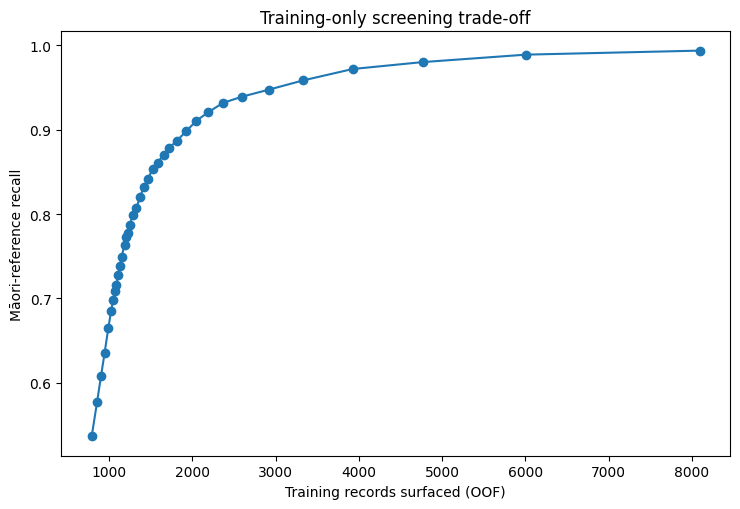

In [17]:
selected_oof = cv_store[selected_name]
thresholds = np.round(np.arange(0.05, 0.951, 0.025), 3)

threshold_rows = []
for threshold in thresholds:
    pred = (selected_oof["prob"] >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_train, pred, labels=[0, 1]).ravel()
    threshold_rows.append({
        "threshold": threshold,
        "maori_recall": recall_score(y_train, pred, zero_division=0),
        "maori_precision": precision_score(y_train, pred, zero_division=0),
        "macro_f1": f1_score(y_train, pred, average="macro", zero_division=0),
        "records_surfaced": int(pred.sum()),
        "reference_maori_surfaced": int(tp),
        "reference_maori_missed": int(fn),
        "additional_records_for_review": int(fp),
    })

threshold_oof_df = pd.DataFrame(threshold_rows)
threshold_oof_df.to_csv(
    OUTPUT_DIR / "training_oof_threshold_review_burden.csv", index=False
)
display(threshold_oof_df.round(4))

fig, ax = plt.subplots(figsize=(7.5, 5.2))
ax.plot(threshold_oof_df["records_surfaced"], threshold_oof_df["maori_recall"], marker="o")
ax.set_xlabel("Training records surfaced (OOF)")
ax.set_ylabel("Māori-reference recall")
ax.set_title("Training-only screening trade-off")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "training_oof_review_burden_curve.png", dpi=200, bbox_inches="tight")
plt.show()

# Part E — Calibration aligned to the same final classifier

## 14. Fit a Platt-style calibrator using out-of-fold decision scores

The calibration model is learned from the selected configuration's **out-of-fold training decision scores**.

Then one final TF-IDF/logistic-regression classifier is fit to the full training set. Its decision score is transformed by the frozen calibrator.

This ensures:

**metadata → final TF-IDF/LR decision → calibrated probability**

and the probability refers to the same classifier whose coefficients are later explained.

In [18]:
selected_oof_decision = selected_oof["decision"].reshape(-1, 1)

# One-dimensional sigmoid mapping from decision score -> Māori-reference probability.
# No class weighting is used in the calibrator.
platt_calibrator = LogisticRegression(
    C=1e6,
    solver="lbfgs",
    max_iter=2000,
    random_state=SEED,
)
platt_calibrator.fit(selected_oof_decision, y_train)

selected_cfg = CONFIGS[selected_name]
final_pipeline = make_pipeline(
    include_phrases=selected_cfg["include_phrases"],
    class_weight=selected_cfg["class_weight"],
)
final_pipeline.fit(X_train_df, y_train)

print("Final classifier fitted on all training records.")
print("Selected config:", selected_name)

Final classifier fitted on all training records.
Selected config: unigram_balanced


# Part F — Held-out test evaluation

## 15. Evaluate the frozen final methodology once

At this point:

- lexical vocabularies are frozen;
- candidate representation is chosen from training CV;
- calibration is frozen from training OOF scores;
- the final TF-IDF/LR model is fitted on all training records.

Now the held-out test set is evaluated.

,model,accuracy,macro_f1,maori_precision,maori_recall,maori_f1,auprc,predicted_maori,tp,fn,fp,tn
0,keyword_strict_specific_phrases,0.9283,0.7454,0.9640,0.3651,0.5296,NaN,139,134,233,5,2946
1,keyword_inclusive_general_cues,0.9699,0.9229,0.8698,0.8556,0.8626,NaN,361,314,53,47,2904
2,tfidf_final_unigram_balanced,0.9662,0.9136,0.8532,0.8392,0.8462,0.9208,361,308,59,53,2898


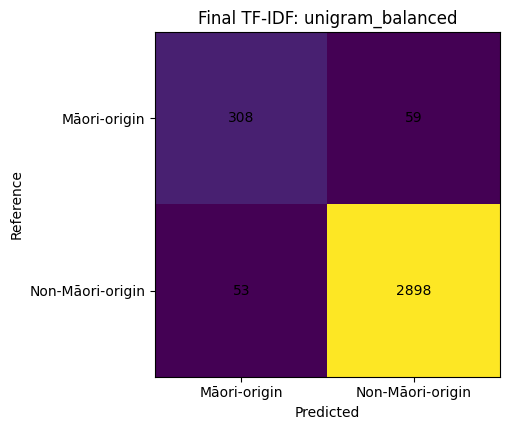

array([[ 308,   59],
       [  53, 2898]])

In [19]:
# Rule baselines
keyword_strict_metrics = metric_row(
    "keyword_strict_specific_phrases",
    y_test,
    test_df["keyword_strict_pred"].to_numpy(),
)
keyword_inclusive_metrics = metric_row(
    "keyword_inclusive_general_cues",
    y_test,
    test_df["keyword_inclusive_pred"].to_numpy(),
)

# Final TF-IDF model
test_pred = final_pipeline.predict(X_test_df)
test_p_raw = final_pipeline.predict_proba(X_test_df)[:, 1]
test_decision = final_pipeline.decision_function(X_test_df)
test_p_calibrated = platt_calibrator.predict_proba(test_decision.reshape(-1, 1))[:, 1]

final_metrics = metric_row(
    f"tfidf_final_{selected_name}",
    y_test,
    test_pred,
    test_p_raw,
)

heldout_summary_df = pd.DataFrame([
    keyword_strict_metrics,
    keyword_inclusive_metrics,
    final_metrics,
])

display(heldout_summary_df.round(4))
heldout_summary_df.to_csv(OUTPUT_DIR / "heldout_traditional_summary.csv", index=False)

show_confusion(
    y_test,
    test_pred,
    f"Final TF-IDF: {selected_name}",
    "heldout_final_tfidf_confusion.png",
)

## 16. Held-out precision–recall curve

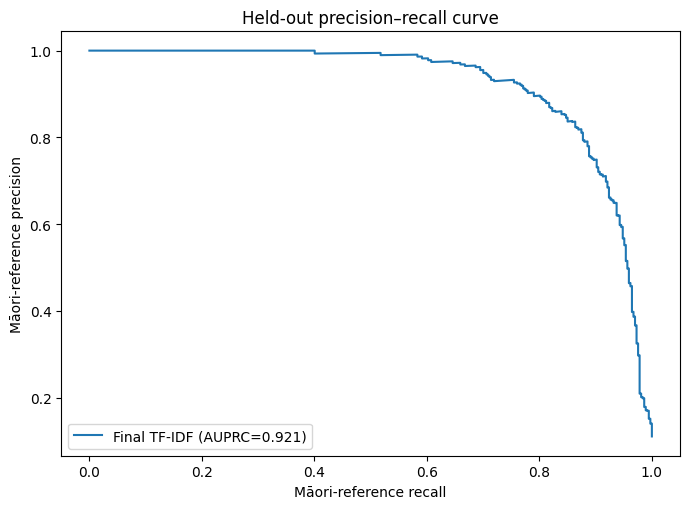

In [20]:
precision, recall, thresholds_pr = precision_recall_curve(y_test, test_p_raw)
ap = average_precision_score(y_test, test_p_raw)

fig, ax = plt.subplots(figsize=(7, 5.2))
ax.plot(recall, precision, label=f"Final TF-IDF (AUPRC={ap:.3f})")
ax.set_xlabel("Māori-reference recall")
ax.set_ylabel("Māori-reference precision")
ax.set_title("Held-out precision–recall curve")
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "heldout_final_precision_recall_curve.png", dpi=200, bbox_inches="tight")
plt.show()

## 17. Held-out calibration diagnostics

Calibration is evaluated against the existing reference labels. It is therefore probability calibration for **agreement with this reference set**, not culturally authoritative probability of Māori-origin status.

,score,brier,ece_10
0,raw_lr_probability,0.03031,0.05869
1,oof_platt_calibrated_probability,0.02514,0.00734


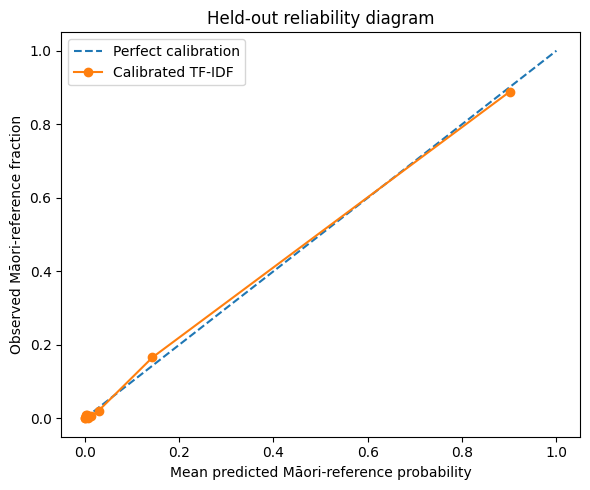

In [21]:
def expected_calibration_error(y_true, probs, n_bins=10):
    y_true = np.asarray(y_true)
    probs = np.asarray(probs)
    bins = np.linspace(0, 1, n_bins + 1)
    ids = np.digitize(probs, bins[1:-1], right=False)

    ece = 0.0
    rows = []
    for b in range(n_bins):
        mask = ids == b
        if not mask.any():
            continue
        mean_p = float(probs[mask].mean())
        observed = float(y_true[mask].mean())
        weight = float(mask.mean())
        ece += weight * abs(mean_p - observed)
        rows.append({
            "bin": b,
            "n": int(mask.sum()),
            "mean_predicted_probability": mean_p,
            "observed_maori_reference_fraction": observed,
            "weight": weight,
        })
    return ece, pd.DataFrame(rows)

brier_raw = brier_score_loss(y_test, test_p_raw)
brier_cal = brier_score_loss(y_test, test_p_calibrated)
ece_raw, ece_raw_df = expected_calibration_error(y_test, test_p_raw)
ece_cal, ece_cal_df = expected_calibration_error(y_test, test_p_calibrated)

calibration_summary_df = pd.DataFrame([
    {"score": "raw_lr_probability", "brier": brier_raw, "ece_10": ece_raw},
    {"score": "oof_platt_calibrated_probability", "brier": brier_cal, "ece_10": ece_cal},
])
display(calibration_summary_df.round(5))
calibration_summary_df.to_csv(OUTPUT_DIR / "heldout_calibration_summary.csv", index=False)

prob_true, prob_pred = calibration_curve(
    y_test, test_p_calibrated, n_bins=10, strategy="quantile"
)

fig, ax = plt.subplots(figsize=(6, 5))
ax.plot([0, 1], [0, 1], linestyle="--", label="Perfect calibration")
ax.plot(prob_pred, prob_true, marker="o", label="Calibrated TF-IDF")
ax.set_xlabel("Mean predicted Māori-reference probability")
ax.set_ylabel("Observed Māori-reference fraction")
ax.set_title("Held-out reliability diagram")
ax.legend()
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "heldout_reliability_diagram.png", dpi=200, bbox_inches="tight")
plt.show()

## 18. Held-out threshold versus review burden

This table is **not used to select the model or retrospectively optimize the experiment**.

It translates the model score into the repository-screening quantities that matter operationally: how many Māori-reference records are surfaced, how many are missed, and how many additional records would require review.

In [22]:
test_threshold_rows = []
for threshold in thresholds:
    pred = (test_p_raw >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred, labels=[0, 1]).ravel()
    test_threshold_rows.append({
        "threshold": threshold,
        "maori_recall": recall_score(y_test, pred, zero_division=0),
        "maori_precision": precision_score(y_test, pred, zero_division=0),
        "macro_f1": f1_score(y_test, pred, average="macro", zero_division=0),
        "records_surfaced": int(pred.sum()),
        "reference_maori_surfaced": int(tp),
        "reference_maori_missed": int(fn),
        "additional_records_for_review": int(fp),
    })

heldout_threshold_df = pd.DataFrame(test_threshold_rows)
heldout_threshold_df.to_csv(
    OUTPUT_DIR / "heldout_threshold_review_burden.csv", index=False
)
display(heldout_threshold_df.round(4))

,threshold,maori_recall,maori_precision,macro_f1,records_surfaced,reference_maori_surfaced,reference_maori_missed,additional_records_for_review
0,0.050,0.9864,0.1961,0.4953,1846,362,5,1484
1,0.075,0.9782,0.2562,0.5952,1401,359,8,1042
2,0.100,0.9728,0.3248,0.6708,1099,357,10,742
3,0.125,0.9673,0.3867,0.7225,918,355,12,563
4,0.150,0.9646,0.4398,0.7596,805,354,13,451
5,0.175,0.9564,0.5014,0.7962,700,351,16,349
6,0.200,0.9510,0.5513,0.8222,633,349,18,284
7,0.225,0.9428,0.6081,0.8483,569,346,21,223
8,0.250,0.9319,0.6490,0.8643,527,342,25,185
9,0.275,0.9237,0.6848,0.8773,495,339,28,156


# Part G — Global interpretability

## 19. Extract field-specific learned coefficients

The final classifier is linear.

Because the analysis target is coded as:

- `1 = maori_origin`
- `0 = non_maori_origin`

then:

- positive coefficient → pushes the decision toward Māori-origin;
- negative coefficient → pushes the decision toward non-Māori-origin.

A coefficient is a learned association with the training reference labels. It is **not** a cultural definition of Māori research.

In [23]:
feature_transformer = final_pipeline.named_steps["features"]
final_lr = final_pipeline.named_steps["lr"]

X_train_final = feature_transformer.transform(X_train_df)
X_test_final = feature_transformer.transform(X_test_df)

if not sparse.issparse(X_train_final):
    X_train_final = sparse.csr_matrix(X_train_final)
if not sparse.issparse(X_test_final):
    X_test_final = sparse.csr_matrix(X_test_final)

feature_names = feature_transformer.get_feature_names_out()
coef = final_lr.coef_[0]
intercept = float(final_lr.intercept_[0])

assert len(feature_names) == len(coef)

def parse_feature_metadata(feature_name):
    block, token = feature_name.split("__", 1)
    if block.endswith("_uni"):
        field = block[:-4]
        feature_block = "unigram"
    elif block.endswith("_phrase"):
        field = block[:-7]
        feature_block = "phrase"
    else:
        field = block
        feature_block = "unknown"
    ngram_n = len(token.split())
    return field, feature_block, token, ngram_n

parsed = [parse_feature_metadata(f) for f in feature_names]

pos_mask = y_train == 1
neg_mask = y_train == 0
df_pos = np.asarray(X_train_final[pos_mask].getnnz(axis=0)).ravel()
df_neg = np.asarray(X_train_final[neg_mask].getnnz(axis=0)).ravel()

global_features_df = pd.DataFrame({
    "full_feature_name": feature_names,
    "field": [x[0] for x in parsed],
    "feature_block": [x[1] for x in parsed],
    "feature": [x[2] for x in parsed],
    "ngram_n": [x[3] for x in parsed],
    "coefficient": coef,
    "direction": np.where(coef > 0, "toward_maori", "toward_non_maori"),
    "train_doc_frequency": df_pos + df_neg,
    "train_maori_doc_frequency": df_pos,
    "train_non_maori_doc_frequency": df_neg,
    "train_maori_prevalence": df_pos / pos_mask.sum(),
    "train_non_maori_prevalence": df_neg / neg_mask.sum(),
})
global_features_df["prevalence_difference_maori_minus_non"] = (
    global_features_df["train_maori_prevalence"]
    - global_features_df["train_non_maori_prevalence"]
)

global_features_df.to_csv(
    OUTPUT_DIR / "global_field_specific_feature_coefficients.csv", index=False
)

top_maori = global_features_df.nlargest(40, "coefficient")
top_non = global_features_df.nsmallest(40, "coefficient")

print("Top Māori-direction features")
display(top_maori.head(30).round(4))
print("Top non-Māori-direction features")
display(top_non.head(30).round(4))

top_maori.to_csv(OUTPUT_DIR / "top_40_maori_direction_features.csv", index=False)
top_non.to_csv(OUTPUT_DIR / "top_40_non_maori_direction_features.csv", index=False)

Top Māori-direction features


,full_feature_name,field,feature_block,feature,ngram_n,coefficient,direction,train_doc_frequency,train_maori_doc_frequency,train_non_maori_doc_frequency,train_maori_prevalence,train_non_maori_prevalence,prevalence_difference_maori_minus_non
11385,abstract_uni__māori,abstract,unigram,māori,1,14.0258,toward_maori,927,870,57,0.5922,0.0048,0.5874
10954,abstract_uni__maori,abstract,unigram,maori,1,8.4718,toward_maori,294,264,30,0.1797,0.0025,0.1772
1466,title_uni__māori,title,unigram,māori,1,7.2391,toward_maori,405,405,0,0.2757,0.0000,0.2757
14041,abstract_uni__te,abstract,unigram,te,1,6.5141,toward_maori,736,519,217,0.3533,0.0184,0.3349
10157,abstract_uni__indigenous,abstract,unigram,indigenous,1,6.3156,toward_maori,625,409,216,0.2784,0.0183,0.2601
1339,title_uni__maori,title,unigram,maori,1,5.5181,toward_maori,154,154,0,0.1048,0.0000,0.1048
6622,abstract_uni__aotearoa,abstract,unigram,aotearoa,1,4.1714,toward_maori,727,363,364,0.2471,0.0308,0.2163
4699,subjects_uni__maori,subjects,unigram,maori,1,3.5947,toward_maori,164,160,4,0.1089,0.0003,0.1086
10466,abstract_uni__iwi,abstract,unigram,iwi,1,3.4751,toward_maori,162,160,2,0.1089,0.0002,0.1087
2206,title_uni__te,title,unigram,te,1,3.3889,toward_maori,374,285,89,0.1940,0.0075,0.1865


Top non-Māori-direction features


,full_feature_name,field,feature_block,feature,ngram_n,coefficient,direction,train_doc_frequency,train_maori_doc_frequency,train_non_maori_doc_frequency,train_maori_prevalence,train_non_maori_prevalence,prevalence_difference_maori_minus_non
2365,title_uni__using,title,unigram,using,1,-1.7613,toward_non_maori,510,11,499,0.0075,0.0423,-0.0348
13795,abstract_uni__study,abstract,unigram,study,1,-1.4288,toward_non_maori,4332,401,3931,0.2730,0.3331,-0.0601
14568,abstract_uni__using,abstract,unigram,using,1,-1.3673,toward_non_maori,3643,216,3427,0.1470,0.2904,-0.1433
2457,title_uni__who,title,unigram,who,1,-1.3163,toward_non_maori,55,5,50,0.0034,0.0042,-0.0008
14044,abstract_uni__teachers,abstract,unigram,teachers,1,-1.3064,toward_non_maori,879,97,782,0.0660,0.0663,-0.0002
4540,subjects_uni__learning,subjects,unigram,learning,1,-1.2066,toward_non_maori,136,1,135,0.0007,0.0114,-0.0108
14900,abstract_uni__work,abstract,unigram,work,1,-1.1499,toward_non_maori,1993,187,1806,0.1273,0.1530,-0.0257
847,title_uni__field,title,unigram,field,1,-1.1367,toward_non_maori,118,0,118,0.0000,0.0100,-0.0100
1152,title_uni__international,title,unigram,international,1,-1.1031,toward_non_maori,153,5,148,0.0034,0.0125,-0.0091
13491,abstract_uni__small,abstract,unigram,small,1,-1.0847,toward_non_maori,1141,54,1087,0.0368,0.0921,-0.0553


## 20. Feature-source summary

In [24]:
field_summary_df = (
    global_features_df.assign(abs_coef=global_features_df["coefficient"].abs())
    .groupby(["field", "feature_block"])
    .agg(
        n_features=("feature", "size"),
        mean_abs_coefficient=("abs_coef", "mean"),
        median_abs_coefficient=("abs_coef", "median"),
        max_abs_coefficient=("abs_coef", "max"),
    )
    .reset_index()
)
display(field_summary_df.round(4))
field_summary_df.to_csv(OUTPUT_DIR / "feature_block_summary.csv", index=False)

,field,feature_block,n_features,mean_abs_coefficient,median_abs_coefficient,max_abs_coefficient
0,abstract,unigram,9000,0.1787,0.1094,14.0258
1,subjects,unigram,3500,0.1165,0.0480,3.5947
2,title,unigram,2500,0.2984,0.2157,7.2391


# Part H — Exact per-record explanations

## 21. Reconstruct every logistic-regression decision

For record \(i\), logistic regression uses:

\[
z_i = b + \sum_j x_{ij}eta_j
\]

where:

- \(b\) = intercept;
- \(x_{ij}\) = record-specific TF-IDF value;
- \(eta_j\) = learned coefficient.

The notebook saves the strongest positive and negative contributions, but it also saves the **sum of all active contributions** and verifies that:

\[
b + \sum_j x_{ij}eta_j
\]

matches `decision_function()`.

This is an exact explanation of the linear classifier, not a generated narrative.

In [25]:
def explain_sparse_row(X_row, feature_names, coefficients, top_k=8):
    indices = X_row.indices
    values = X_row.data

    rows = []
    for idx, value in zip(indices, values):
        field, block, token, ngram_n = parse_feature_metadata(feature_names[idx])
        contribution = float(value * coefficients[idx])
        rows.append({
            "field": field,
            "feature_block": block,
            "feature": token,
            "ngram_n": int(ngram_n),
            "tfidf": float(value),
            "coefficient": float(coefficients[idx]),
            "contribution": contribution,
        })

    toward_maori = sorted(
        [r for r in rows if r["contribution"] > 0],
        key=lambda r: r["contribution"],
        reverse=True,
    )[:top_k]

    toward_non = sorted(
        [r for r in rows if r["contribution"] < 0],
        key=lambda r: r["contribution"],
    )[:top_k]

    total_contribution = float(sum(r["contribution"] for r in rows))
    return toward_maori, toward_non, total_contribution, len(rows)

reconstructed_scores = []
top_maori_json = []
top_non_json = []
active_feature_counts = []
sum_contributions = []

for i in range(X_test_final.shape[0]):
    pos, neg, total, n_active = explain_sparse_row(
        X_test_final[i], feature_names, coef, top_k=8
    )
    reconstructed = intercept + total

    top_maori_json.append(json.dumps(pos, ensure_ascii=False))
    top_non_json.append(json.dumps(neg, ensure_ascii=False))
    sum_contributions.append(total)
    reconstructed_scores.append(reconstructed)
    active_feature_counts.append(n_active)

reconstructed_scores = np.asarray(reconstructed_scores)

max_reconstruction_error = np.max(np.abs(reconstructed_scores - test_decision))
print("Maximum decision-score reconstruction error:", max_reconstruction_error)
assert np.allclose(reconstructed_scores, test_decision, atol=1e-8), (
    "Local contribution reconstruction does not match decision_function()."
)

Maximum decision-score reconstruction error: 1.0658141036401503e-14


## 22. Build the complete per-record output

This is the traditional-model analogue of an auditable classification output.

For each paper it contains:

- reference label for comparison;
- TF-IDF prediction;
- raw and calibrated Māori-reference probability;
- logistic decision score;
- intercept;
- sum of feature contributions;
- reconstructed decision score;
- strongest features pushing toward Māori;
- strongest features pushing toward non-Māori;
- lexical-condition indicators.

No LLM reason or LLM confidence is used.

In [26]:
per_record_df = test_df.copy()

per_record_df["tfidf_prediction"] = np.where(
    test_pred == 1, "maori_origin", "non_maori_origin"
)
per_record_df["p_maori_raw"] = test_p_raw
per_record_df["p_maori_calibrated"] = test_p_calibrated
per_record_df["decision_score"] = test_decision
per_record_df["decision_margin_abs"] = np.abs(test_decision)
per_record_df["lr_intercept"] = intercept
per_record_df["sum_feature_contributions"] = sum_contributions
per_record_df["reconstructed_decision_score"] = reconstructed_scores
per_record_df["decision_reconstruction_error"] = (
    per_record_df["reconstructed_decision_score"] - per_record_df["decision_score"]
)
per_record_df["active_feature_count"] = active_feature_counts
per_record_df["top_features_toward_maori"] = top_maori_json
per_record_df["top_features_toward_non_maori"] = top_non_json
per_record_df["reference_agreement"] = test_pred == y_test

output_columns = [
    c for c in [
        ID_COL,
        "title",
        "subjects",
        "abstract",
        "reference_label",
        "tfidf_prediction",
        "p_maori_raw",
        "p_maori_calibrated",
        "decision_score",
        "decision_margin_abs",
        "lr_intercept",
        "sum_feature_contributions",
        "reconstructed_decision_score",
        "decision_reconstruction_error",
        "active_feature_count",
        "specific_hits",
        "general_maori_hits",
        "broad_context_hits",
        "top_features_toward_maori",
        "top_features_toward_non_maori",
        "reference_agreement",
    ] if c in per_record_df.columns
]

per_record_df[output_columns].to_csv(
    OUTPUT_DIR / "tfidf_per_record_explainable_output.csv",
    index=False,
)
display(per_record_df[output_columns].head(5))
print("Saved:", OUTPUT_DIR / "tfidf_per_record_explainable_output.csv")

,record_id_hash,title,subjects,abstract,reference_label,tfidf_prediction,p_maori_raw,p_maori_calibrated,decision_score,decision_margin_abs,...,sum_feature_contributions,reconstructed_decision_score,decision_reconstruction_error,active_feature_count,specific_hits,general_maori_hits,broad_context_hits,top_features_toward_maori,top_features_toward_non_maori,reference_agreement
0,f3216214e6f1b0b1b79207699a6584de62328c76eccef4...,Exploring the experiences of female students' ...,Transitions,Educational transitions take place when childr...,non_maori_origin,non_maori_origin,0.090881,0.012338,-2.302930,2.302930,...,0.155470,-2.302930,0.000000e+00,253,[],[],"[""education"", ""environment""]","[{""field"": ""abstract"", ""feature_block"": ""unigr...","[{""field"": ""abstract"", ""feature_block"": ""unigr...",True
1,3453bdd8f4f86774ba2a95c9cbc58e28a48a55eb739ea0...,Distributed Operating Systems on Wireless Sens...,Wireless Sensor Networks,This thesis proposes the use of traditional di...,non_maori_origin,non_maori_origin,0.015557,0.000628,-4.147541,4.147541,...,-1.689142,-4.147541,0.000000e+00,180,[],[],"[""environment""]","[{""field"": ""abstract"", ""feature_block"": ""unigr...","[{""field"": ""title"", ""feature_block"": ""unigram""...",True
2,a1eb558034276279b926230f75d3d8c3f74dc9c2f977e0...,Learning to link with Wikipedia,computer science,This paper describes a new technique for obtai...,non_maori_origin,non_maori_origin,0.018203,0.000813,-3.987791,3.987791,...,-1.529391,-3.987791,-8.881784e-16,68,[],[],[],"[{""field"": ""title"", ""feature_block"": ""unigram""...","[{""field"": ""subjects"", ""feature_block"": ""unigr...",True
3,b2081e367b06428499265f6f9c854d3c5a71f6d73898ba...,The coherence of traumatic and non-traumatic m...,Memory,There is contention in the scientific literatu...,non_maori_origin,non_maori_origin,0.043297,0.003445,-3.095416,3.095416,...,-0.637017,-3.095416,0.000000e+00,151,[],[],[],"[{""field"": ""abstract"", ""feature_block"": ""unigr...","[{""field"": ""subjects"", ""feature_block"": ""unigr...",True
4,67fa000fc39932995bfda55aedcb77354fd80725b0a78b...,Stimulus Equivalence: A Comparison of Operant ...,Behavioural Psychology,Previous studies comparing the effectiveness o...,non_maori_origin,non_maori_origin,0.053044,0.004861,-2.882134,2.882134,...,-0.423735,-2.882134,0.000000e+00,155,[],[],[],"[{""field"": ""subjects"", ""feature_block"": ""unigr...","[{""field"": ""title"", ""feature_block"": ""unigram""...",True


Saved: /content/tfidf_traditional_revised_outputs/tfidf_per_record_explainable_output.csv


# Part I — Lexical-condition analysis

## 23. Define groups from text only

Crucially, the reference label is **not used to create these groups**.

Each record is assigned to exactly one lexical condition:

1. `specific_maori_phrase_present`
2. `general_maori_cue_only`
3. `broad_context_only`
4. `no_selected_lexical_signal`

Only after the groups exist do we compare TF-IDF predictions with the reference labels.

In [27]:
def lexical_condition(row):
    if row["has_specific_maori_phrase"]:
        return "specific_maori_phrase_present"
    if row["has_general_maori_cue"]:
        return "general_maori_cue_only"
    if row["has_broad_context_cue"]:
        return "broad_context_only"
    return "no_selected_lexical_signal"

per_record_df["lexical_condition"] = per_record_df.apply(
    lexical_condition, axis=1
)

print(per_record_df["lexical_condition"].value_counts())

lexical_condition
broad_context_only               1524
no_selected_lexical_signal       1433
general_maori_cue_only            222
specific_maori_phrase_present     139
Name: count, dtype: int64


## 24. Evaluate TF-IDF within each lexical condition

,lexical_condition,n,reference_maori_n,reference_non_maori_n,reference_maori_fraction,agreement_rate,predicted_maori_rate,mean_raw_p_maori,mean_calibrated_p_maori,maori_recall_within_condition,maori_precision_within_condition,auprc_within_condition
0,broad_context_only,1524,37,1487,0.0243,0.9633,0.0387,0.1246,0.0489,0.5405,0.3390,0.3674
1,no_selected_lexical_signal,1433,16,1417,0.0112,0.9916,0.0084,0.0603,0.0140,0.5000,0.6667,0.6378
2,specific_maori_phrase_present,139,134,5,0.9640,0.9424,0.9209,0.9094,0.9009,0.9478,0.9922,0.9992
3,general_maori_cue_only,222,180,42,0.8108,0.8378,0.7297,0.7020,0.6640,0.8500,0.9444,0.9760


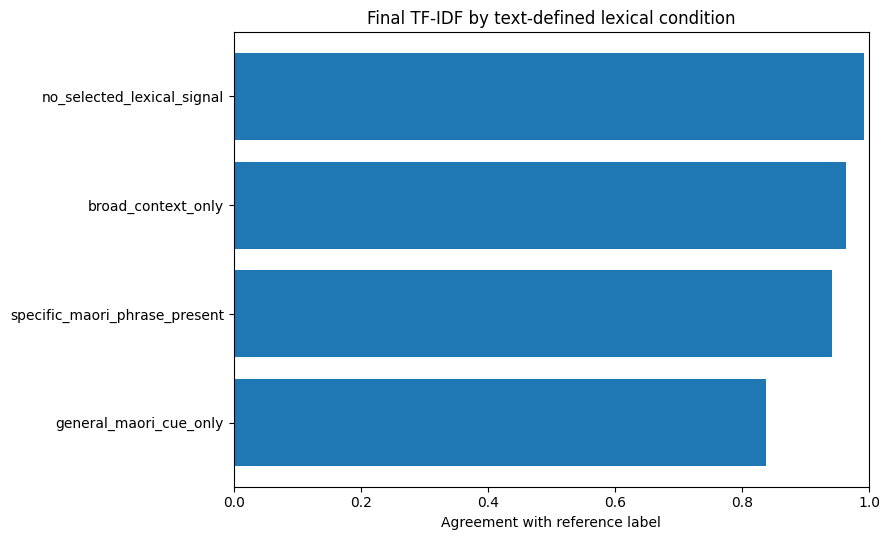

In [28]:
condition_rows = []

for condition, g in per_record_df.groupby("lexical_condition", sort=False):
    y_g = g["y"].to_numpy(dtype=int)
    pred_g = (g["tfidf_prediction"] == "maori_origin").astype(int).to_numpy()
    p_g = g["p_maori_raw"].to_numpy()

    row = {
        "lexical_condition": condition,
        "n": len(g),
        "reference_maori_n": int(y_g.sum()),
        "reference_non_maori_n": int((1 - y_g).sum()),
        "reference_maori_fraction": float(y_g.mean()),
        "agreement_rate": float((pred_g == y_g).mean()),
        "predicted_maori_rate": float(pred_g.mean()),
        "mean_raw_p_maori": float(p_g.mean()),
        "mean_calibrated_p_maori": float(g["p_maori_calibrated"].mean()),
    }

    # These are meaningful even when one class is sparse; zero_division avoids crashes.
    row["maori_recall_within_condition"] = recall_score(
        y_g, pred_g, pos_label=1, zero_division=0
    )
    row["maori_precision_within_condition"] = precision_score(
        y_g, pred_g, pos_label=1, zero_division=0
    )

    if len(np.unique(y_g)) == 2:
        row["auprc_within_condition"] = average_precision_score(y_g, p_g)
    else:
        row["auprc_within_condition"] = np.nan

    condition_rows.append(row)

lexical_condition_results_df = pd.DataFrame(condition_rows)
display(lexical_condition_results_df.round(4))
lexical_condition_results_df.to_csv(
    OUTPUT_DIR / "lexical_condition_results.csv", index=False
)

fig, ax = plt.subplots(figsize=(9, 5.5))
plot_df = lexical_condition_results_df.sort_values("agreement_rate")
ax.barh(plot_df["lexical_condition"], plot_df["agreement_rate"])
ax.set_xlim(0, 1)
ax.set_xlabel("Agreement with reference label")
ax.set_title("Final TF-IDF by text-defined lexical condition")
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "lexical_condition_agreement.png", dpi=200, bbox_inches="tight")
plt.show()

## 25. Cross-tabulate lexical condition by reference label

This table is particularly useful for understanding lexical overlap.

For example:

- a `general_maori_cue_only` record can still have a non-Māori reference label;
- a `no_selected_lexical_signal` record can still have a Māori reference label.

Those are precisely the situations where simple keyword presence is insufficient.

In [29]:
condition_reference_table = pd.crosstab(
    per_record_df["lexical_condition"],
    per_record_df["reference_label"],
    margins=True,
)
display(condition_reference_table)
condition_reference_table.to_csv(
    OUTPUT_DIR / "lexical_condition_by_reference_label.csv"
)

reference_label,maori_origin,non_maori_origin,All
lexical_condition,,,
broad_context_only,37,1487,1524
general_maori_cue_only,180,42,222
no_selected_lexical_signal,16,1417,1433
specific_maori_phrase_present,134,5,139
All,367,2951,3318


# Part J — Systematic reference-relative disagreement analysis

## 26. Label disagreement types

The terms below describe disagreement **relative to the existing reference labels**. They do not imply independently verified truth.

In [30]:
def disagreement_type(row):
    ref = row["reference_label"]
    pred = row["tfidf_prediction"]
    if ref == pred:
        return "agreement"
    if ref == "maori_origin" and pred == "non_maori_origin":
        return "reference_maori_predicted_non_maori"
    return "reference_non_maori_predicted_maori"

per_record_df["disagreement_type"] = per_record_df.apply(
    disagreement_type, axis=1
)

disagreements_df = per_record_df[
    per_record_df["disagreement_type"] != "agreement"
].copy()

print("Total disagreements:", len(disagreements_df))
print(disagreements_df["disagreement_type"].value_counts())
print("\nBy lexical condition:")
display(pd.crosstab(
    disagreements_df["lexical_condition"],
    disagreements_df["disagreement_type"],
))

Total disagreements: 112
disagreement_type
reference_maori_predicted_non_maori    59
reference_non_maori_predicted_maori    53
Name: count, dtype: int64

By lexical condition:


disagreement_type,reference_maori_predicted_non_maori,reference_non_maori_predicted_maori
lexical_condition,,
broad_context_only,17,39
general_maori_cue_only,27,9
no_selected_lexical_signal,8,4
specific_maori_phrase_present,7,1


## 27. Save disagreement records with exact lexical explanations

In [31]:
disagreement_columns = [
    c for c in [
        ID_COL,
        "title",
        "subjects",
        "abstract",
        "reference_label",
        "tfidf_prediction",
        "p_maori_raw",
        "p_maori_calibrated",
        "decision_score",
        "decision_margin_abs",
        "lexical_condition",
        "specific_hits",
        "general_maori_hits",
        "broad_context_hits",
        "top_features_toward_maori",
        "top_features_toward_non_maori",
        "disagreement_type",
    ] if c in disagreements_df.columns
]

disagreements_df[disagreement_columns].sort_values(
    "decision_margin_abs", ascending=False
).to_csv(
    OUTPUT_DIR / "tfidf_reference_disagreements_explained.csv",
    index=False,
)

## 28. Reproducible representative cases

Cases are not hand-picked because they tell a preferred story.

For each disagreement type, select:

- the 4 largest decision-margin disagreements;
- the 4 records closest to the decision boundary.

This creates a reproducible qualitative audit set.

In [32]:
case_frames = []

for dtype, g in disagreements_df.groupby("disagreement_type"):
    high_margin = g.nlargest(4, "decision_margin_abs").copy()
    high_margin["case_selection"] = "largest_decision_margin"

    near_boundary = g.nsmallest(4, "decision_margin_abs").copy()
    near_boundary["case_selection"] = "closest_to_boundary"

    case_frames.extend([high_margin, near_boundary])

representative_cases_df = (
    pd.concat(case_frames, ignore_index=True)
    if case_frames
    else pd.DataFrame()
)

case_columns = [
    c for c in disagreement_columns + ["case_selection"]
    if c in representative_cases_df.columns
]

representative_cases_df[case_columns].to_csv(
    OUTPUT_DIR / "representative_tfidf_cases.csv",
    index=False,
)

display(representative_cases_df[case_columns])

,record_id_hash,title,subjects,abstract,reference_label,tfidf_prediction,p_maori_raw,p_maori_calibrated,decision_score,decision_margin_abs,lexical_condition,specific_hits,general_maori_hits,broad_context_hits,top_features_toward_maori,top_features_toward_non_maori,disagreement_type,case_selection
0,72ff6f6b44dd7705095090e3e0650123c9037b3cc9de82...,Kaitiakitanga: protecting New Zealand's native...,geography,Species diversity is a very important componen...,maori_origin,non_maori_origin,0.029024,0.001762,-3.510168,3.510168,general_maori_cue_only,[],"[""kaitiakitanga""]","[""new zealand"", ""health"", ""environment""]","[{""field"": ""abstract"", ""feature_block"": ""unigr...","[{""field"": ""subjects"", ""feature_block"": ""unigr...",reference_maori_predicted_non_maori,largest_decision_margin
1,a53ead8f037d7813df267bec29e280cefd14a4c4d37763...,The relationship between on-water performance ...,None,Objectives: The aim of the present study was t...,maori_origin,non_maori_origin,0.033912,0.002285,-3.349471,3.349471,no_selected_lexical_signal,[],[],[],"[{""field"": ""abstract"", ""feature_block"": ""unigr...","[{""field"": ""title"", ""feature_block"": ""unigram""...",reference_maori_predicted_non_maori,largest_decision_margin
2,f5e06b5f7f1ac844fe2db165aa39d79943d68f8343bc1f...,How Maui captured the sun: using a MUD for edu...,computer science,"MUDs (Multi-User Dungeons) are text-based, mul...",maori_origin,non_maori_origin,0.041125,0.003159,-3.149133,3.149133,broad_context_only,[],[],"[""education""]","[{""field"": ""title"", ""feature_block"": ""unigram""...","[{""field"": ""subjects"", ""feature_block"": ""unigr...",reference_maori_predicted_non_maori,largest_decision_margin
3,4ab87a815d21adcaf99980d9038a1908e7409c2ed2bcc8...,"The source, composition and typology of ‘Limes...",adzes,Collections of stone adzes (toki) from the eas...,maori_origin,non_maori_origin,0.041737,0.003238,-3.133738,3.133738,broad_context_only,[],[],"[""new zealand""]","[{""field"": ""abstract"", ""feature_block"": ""unigr...","[{""field"": ""title"", ""feature_block"": ""unigram""...",reference_maori_predicted_non_maori,largest_decision_margin
4,52d971d870d35f20682db15f21372aefc78615ccc0cdbb...,Catchment and lake water quality modelling to ...,None,"Lake Tutira is an important ecological, histor...",maori_origin,non_maori_origin,0.499429,0.342286,-0.002283,0.002283,broad_context_only,[],[],"[""new zealand"", ""community""]","[{""field"": ""abstract"", ""feature_block"": ""unigr...","[{""field"": ""title"", ""feature_block"": ""unigram""...",reference_maori_predicted_non_maori,closest_to_boundary
5,48d0cf4f57eb7782eb62ed10b62620d94a33a5fbd1ac43...,A critical analysis of Section 27 of the Sente...,Section 27,This thesis analyses the effectiveness of Sect...,maori_origin,non_maori_origin,0.495862,0.337098,-0.016552,0.016552,specific_maori_phrase_present,"[""maori culture""]","[""maori""]","[""new zealand"", ""community"", ""education"", ""col...","[{""field"": ""abstract"", ""feature_block"": ""unigr...","[{""field"": ""abstract"", ""feature_block"": ""unigr...",reference_maori_predicted_non_maori,closest_to_boundary
6,4019dd6506e83a5dc0a398602d57f1a354123ebc144f1d...,Rangatahi and complex entanglements of sexuali...,"Rangatahi,sexuality,sexuality education,New ma...",This research is an exploration with rangatahi...,maori_origin,non_maori_origin,0.489970,0.328612,-0.040127,0.040127,general_maori_cue_only,[],"[""maori""]","[""aotearoa"", ""indigenous"", ""health"", ""educatio...","[{""field"": ""abstract"", ""feature_block"": ""unigr...","[{""field"": ""title"", ""feature_block"": ""unigram""...",reference_maori_predicted_non_maori,closest_to_boundary
7,a14dee2da5b06d9f6ae6c253c263dfbe293d4c33f24a09...,Population diversity in Aotearoa New Zealand: ...,None,CaDDANZ was a New Zealand Government-funded pr...,maori_origin,non_maori_origin,0.478323,0.312153,-0.086764,0.086764,specific_maori_phrase_present,"[""tangata whenua""]","[""whenua""]","[""aotearoa"", ""new

# Part K — Uncertainty on final held-out results

## 29. Stratified bootstrap 95% confidence intervals

This quantifies uncertainty around the final held-out metrics. It does not alter predictions or select a model.

In [33]:
def stratified_bootstrap_indices(y, rng):
    y = np.asarray(y)
    pos = np.where(y == 1)[0]
    neg = np.where(y == 0)[0]
    pos_s = rng.choice(pos, size=len(pos), replace=True)
    neg_s = rng.choice(neg, size=len(neg), replace=True)
    idx = np.concatenate([pos_s, neg_s])
    rng.shuffle(idx)
    return idx

def bootstrap_final_ci(y_true, y_pred, score, n_boot=BOOTSTRAP_N, seed=SEED):
    rng = np.random.default_rng(seed)
    metrics = {
        "accuracy": [],
        "macro_f1": [],
        "maori_precision": [],
        "maori_recall": [],
        "maori_f1": [],
        "auprc": [],
    }

    for _ in range(n_boot):
        idx = stratified_bootstrap_indices(y_true, rng)
        yt = y_true[idx]
        yp = y_pred[idx]
        sc = score[idx]

        metrics["accuracy"].append(accuracy_score(yt, yp))
        metrics["macro_f1"].append(f1_score(yt, yp, average="macro", zero_division=0))
        metrics["maori_precision"].append(precision_score(yt, yp, zero_division=0))
        metrics["maori_recall"].append(recall_score(yt, yp, zero_division=0))
        metrics["maori_f1"].append(f1_score(yt, yp, zero_division=0))
        metrics["auprc"].append(average_precision_score(yt, sc))

    point = metric_row("final", y_true, y_pred, score)

    rows = []
    for metric, values in metrics.items():
        arr = np.asarray(values)
        rows.append({
            "metric": metric,
            "estimate": point[metric],
            "ci_lower_95": np.quantile(arr, 0.025),
            "ci_upper_95": np.quantile(arr, 0.975),
            "bootstrap_n": n_boot,
        })
    return pd.DataFrame(rows)

bootstrap_final_df = bootstrap_final_ci(
    y_test, test_pred, test_p_raw
)
display(bootstrap_final_df.round(4))
bootstrap_final_df.to_csv(
    OUTPUT_DIR / "heldout_final_bootstrap_95ci.csv", index=False
)

,metric,estimate,ci_lower_95,ci_upper_95,bootstrap_n
0,accuracy,0.9662,0.9596,0.9720,2000
1,macro_f1,0.9136,0.8972,0.9282,2000
2,maori_precision,0.8532,0.8187,0.8856,2000
3,maori_recall,0.8392,0.8011,0.8747,2000
4,maori_f1,0.8462,0.8172,0.8722,2000
5,auprc,0.9208,0.8992,0.9402,2000


# Part L — Reproducibility and export

## 30. Save model objects and methodology manifest

In [34]:
# Save fitted objects
joblib.dump(final_pipeline, OUTPUT_DIR / "final_tfidf_logistic_pipeline.joblib")
joblib.dump(platt_calibrator, OUTPUT_DIR / "oof_platt_calibrator.joblib")

manifest = {
    "dataset_id": DATASET_ID,
    "label_column": LABEL_COL,
    "positive_analysis_class": "maori_origin",
    "content_fields": CONTENT_FIELDS,
    "train_rows": int(len(train_df)),
    "test_rows": int(len(test_df)),
    "seed": SEED,
    "cv_folds": N_SPLITS,
    "selected_config": selected_name,
    "config_definition": CONFIGS[selected_name],
    "unigram_max_features": UNIGRAM_MAX,
    "phrase_max_features": PHRASE_MAX,
    "min_df": MIN_DF,
    "logistic_C": LR_C,
    "logistic_solver": LR_SOLVER,
    "calibration": "logistic sigmoid fitted to selected model out-of-fold training decision scores",
    "specific_maori_phrases": SPECIFIC_MAORI_PHRASES,
    "general_maori_cues": GENERAL_MAORI_CUES,
    "broad_context_cues": BROAD_CONTEXT_CUES,
    "test_used_for_model_selection": False,
    "llm_outputs_used_as_features": False,
    "interpretation_note": (
        "All downstream performance is agreement with the existing reference labels, "
        "not independently Māori-expert-validated ground truth."
    ),
}

with open(OUTPUT_DIR / "methodology_manifest.json", "w", encoding="utf-8") as f:
    json.dump(manifest, f, indent=2, ensure_ascii=False)

print(json.dumps(manifest, indent=2, ensure_ascii=False))

{
  "dataset_id": "dinushiTJ/nz_research_commons_classification",
  "label_column": "classification_label",
  "positive_analysis_class": "maori_origin",
  "content_fields": [
    "title",
    "subjects",
    "abstract"
  ],
  "train_rows": 13271,
  "test_rows": 3318,
  "seed": 42,
  "cv_folds": 5,
  "selected_config": "unigram_balanced",
  "config_definition": {
    "include_phrases": false,
    "class_weight": "balanced"
  },
  "unigram_max_features": {
    "title": 2500,
    "subjects": 3500,
    "abstract": 9000
  },
  "phrase_max_features": {
    "title": 1800,
    "subjects": 2800,
    "abstract": 7000
  },
  "min_df": 1,
  "logistic_C": 1.0,
  "logistic_solver": "liblinear",
  "calibration": "logistic sigmoid fitted to selected model out-of-fold training decision scores",
  "specific_maori_phrases": [
    "te reo maori",
    "kaupapa maori",
    "matauranga maori",
    "tino rangatiratanga",
    "te tiriti o waitangi",
    "treaty of waitangi",
    "waitangi tribunal",
    "treat

## 31. Save a compact research-results workbook as CSV tables

In [35]:
# Compact summary of the most paper-relevant outputs.
research_tables = {
    "01_cv_model_selection.csv": cv_summary_df,
    "02_heldout_traditional_summary.csv": heldout_summary_df,
    "03_heldout_final_bootstrap_95ci.csv": bootstrap_final_df,
    "04_training_threshold_review_burden.csv": threshold_oof_df,
    "05_heldout_threshold_review_burden.csv": heldout_threshold_df,
    "06_global_top_maori_features.csv": top_maori,
    "07_global_top_non_maori_features.csv": top_non,
    "08_lexical_condition_results.csv": lexical_condition_results_df,
    "09_representative_cases.csv": representative_cases_df[case_columns],
}

for filename, df in research_tables.items():
    df.to_csv(OUTPUT_DIR / filename, index=False)

print("Core research tables saved.")

Core research tables saved.


## 32. Zip all outputs

In [36]:
import shutil

archive_path = shutil.make_archive(
    str(OUTPUT_DIR),
    "zip",
    root_dir=OUTPUT_DIR,
)

print("Output archive:", archive_path)
print("\nMain per-record file:")
print(OUTPUT_DIR / "tfidf_per_record_explainable_output.csv")

Output archive: /content/tfidf_traditional_revised_outputs.zip

Main per-record file:
/content/tfidf_traditional_revised_outputs/tfidf_per_record_explainable_output.csv


# Interpretation checklist after running

Do **not** write the paper before inspecting the actual outputs.

Use the completed results to answer these questions:

1. How much does a strict explicit-phrase keyword search retrieve?
2. What is gained and lost by an inclusive Māori-cue search?
3. Which TF-IDF representation wins under **training-only** cross-validation?
4. Does adding phrase information improve AUPRC, or do unigrams already capture most of the lexical signal?
5. Does class weighting improve ranking (AUPRC), or mainly alter the precision/recall operating point?
6. What exact class weights were applied?
7. Which title, subject, and abstract features receive the strongest coefficients?
8. Are the strongest coefficients common/stable signals or rare terms?
9. For each individual paper, can the model decision be reconstructed exactly from the intercept and feature contributions?
10. Which lexical condition is hardest:
    - specific Māori phrase present;
    - general Māori cue only;
    - broad contextual cues only;
    - no selected lexical signal?
11. How many additional records must be reviewed to achieve different Māori-reference recall levels?
12. Are the calibrated probabilities reasonably aligned with observed reference-label frequencies?
13. What kinds of high-margin disagreements remain?

Only after these answers are known should the TF-IDF methodology/results text in the paper be rewritten.